# 05. Lớp quyết định FLY / CONDITIONAL / NO-FLY

Trả lời hai câu hỏi phụ:

- **Câu hỏi phụ 1:** quyết định dựa trên năng lượng dự đoán có ít trường hợp cho bay sai (false-safe) hơn ngưỡng % pin cố định không?
- **Câu hỏi phụ 2:** phán quyết 3 mức có giảm huỷ chuyến không cần thiết so với 2 mức mà không tăng cho bay sai không?

**Thiết kế kịch bản (bán mô phỏng).** Dữ liệu CMU không có % pin (SoC), độ chai pin (SoH) hay nhiệt độ có kiểm soát, nên trạng thái pin phải mô phỏng. Nhưng **năng lượng chuyến bay cần là năng lượng đo thật** của 192 chuyến, không lấy từ một mô hình. Mỗi chuyến được ghép với 25 trạng thái pin ngẫu nhiên (seed 301), ra 4.800 kịch bản. Như vậy nhãn "đủ pin / không đủ pin" không bị vòng lặp kiểu "mô hình tự chấm mô hình".

**Giả định (ghi rõ để hội đồng soi):**

| Thông số | Giá trị | Nguồn / lý do |
|---|---|---|
| Năng lượng danh định pin | 99,9 Wh | TB47D 4500 mAh (bài báo CMU ghi 4500 mAh); chạy độ nhạy với 129,96 Wh |
| SoC lúc cất cánh | đều 0,15 – 1,00 | phủ cả vùng pin yếu |
| SoH | đều 0,70 – 1,00 | giả định, pin đã dùng đến lúc nên thay |
| Nhiệt độ | đều −10 – 40 °C | dải hoạt động của DJI M100 |
| Hệ số nhiệt độ k(T) | 1 khi T ≥ 20 °C, giảm tuyến tính còn 0,75 ở −10 °C | giả định đơn giản |
| Dự trữ hạ cánh | 20% SoC | luật cứng: SoC < 20% thì NO-FLY |

Năng lượng dùng được: **E_avail = 99,9 × SoH × k(T) × (SoC − 0,20)**. Kịch bản **không đủ pin** (nhãn thật) khi năng lượng đo thật của chuyến lớn hơn E_avail.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

df = pd.read_csv(PROCESSED / "flight_level.csv")
FEATURE = ["speed", "payload", "altitude"]
X, y = df[FEATURE], df["E_Wh"]
print("Số chuyến:", len(df))

Số chuyến: 192


## 1. Dự đoán năng lượng cho từng chuyến, không nhìn chính chuyến đó

Dùng 5-fold (seed 301): mỗi chuyến được dự đoán bởi mô hình train trên 4/5 chuyến còn lại. Trong mỗi fold, **hệ số an toàn q90** được tính chỉ từ tập train (vòng 5-fold lồng bên trong): là phân vị 90% của tỉ số năng lượng thật / dự đoán. Cận trên dự đoán = dự đoán × q90.

In [2]:
def them_speed2(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack([X, X[:, 0] ** 2])

MO_HINH = {
    "B2": LinearRegression(),
    "M1": make_pipeline(FunctionTransformer(them_speed2), LinearRegression()),
}

ngoai = KFold(n_splits=5, shuffle=True, random_state=SEED)
du_doan = {k: np.zeros(len(df)) for k in MO_HINH}
q90 = {k: np.zeros(len(df)) for k in MO_HINH}
for tr, te in ngoai.split(X):
    trong = KFold(n_splits=5, shuffle=True, random_state=SEED)
    for ten, m in MO_HINH.items():
        oof_train = cross_val_predict(clone(m), X.iloc[tr], y.iloc[tr], cv=trong)
        q = np.quantile(y.iloc[tr] / oof_train, 0.90)
        du_doan[ten][te] = clone(m).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
        q90[ten][te] = q

for ten in MO_HINH:
    print(f"{ten}: MAE = {np.abs(y - du_doan[ten]).mean():.2f} Wh, q90 trung bình = {q90[ten].mean():.3f}")

B2: MAE = 1.47 Wh, q90 trung bình = 1.106


M1: MAE = 0.84 Wh, q90 trung bình = 1.050


## 2. Sinh 4.800 kịch bản

In [3]:
E_NOM = 99.9
SOC_MIN = 0.20
DU_TRU = 1.20
K = 25

def k_nhiet(t):
    return np.where(t >= 20, 1.0, 1 - 0.25 * (20 - np.clip(t, -10, 20)) / 30)

def sinh_kich_ban(seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(df) * K
    kb = df.loc[np.repeat(df.index, K), ["flight", "route", "speed", "payload", "altitude", "E_Wh"]].reset_index(drop=True)
    kb["soc"] = rng.uniform(0.15, 1.0, n)
    kb["soh"] = rng.uniform(0.70, 1.0, n)
    kb["nhiet_do"] = rng.uniform(-10, 40, n)
    for ten in MO_HINH:
        kb[f"E_{ten}"] = np.repeat(du_doan[ten], K)
        kb[f"U_{ten}"] = np.repeat(du_doan[ten] * q90[ten], K)
    return kb

def e_avail(kb, e_nom=E_NOM, soc=None):
    soc = kb["soc"] if soc is None else soc
    return e_nom * kb["soh"] * k_nhiet(kb["nhiet_do"]) * np.clip(soc - SOC_MIN, 0, None)

kb = sinh_kich_ban()
kb["E_avail"] = e_avail(kb)
kb["khong_du"] = kb["E_Wh"] > kb["E_avail"]          # nhãn thật: dùng năng lượng ĐO THẬT
print("Số kịch bản:", len(kb), "| không đủ pin:", int(kb["khong_du"].sum()), f"({kb['khong_du'].mean():.1%})")

Số kịch bản: 4800 | không đủ pin: 1857 (38.7%)


## 3. Các cách ra quyết định

Mọi cách đều xét **luật cứng trước**: SoC < 20% thì NO-FLY, không cần mô hình.

| Mã | Cách | FLY khi |
|---|---|---|
| Q0 | Ngưỡng % pin cố định | SoC ≥ 30% / 40% / 50% / 60% |
| Q1 | Dự đoán B2, nhị phân | E_avail ≥ 1,2 × dự đoán B2 |
| Q2 | Dự đoán M1, nhị phân | E_avail ≥ 1,2 × dự đoán M1 |
| Q3 | Cận trên M1, nhị phân | E_avail ≥ 1,2 × cận trên M1 |
| Q4 | **Cận trên M1, 3 mức (đề xuất)** | FLY khi E_avail ≥ 1,2 × cận trên; CONDITIONAL khi 1,0 – 1,2 × cận trên; NO-FLY khi dưới |

CONDITIONAL nghĩa là bay chỉ khi áp dụng biện pháp: thay pin, giảm tải, hạ độ cao hoặc có người giám sát.

In [4]:
def phan_quyet(kb, cach, e_av=None, du_tru=DU_TRU):
    e_av = kb["E_avail"] if e_av is None else e_av
    cung = kb["soc"] < SOC_MIN
    if cach.startswith("Q0"):
        nguong = float(cach.split("≥")[1].strip(" %")) / 100
        v = np.where(kb["soc"] >= nguong, "FLY", "NO-FLY")
    else:
        cot = {"Q1": "E_B2", "Q2": "E_M1", "Q3": "U_M1", "Q4": "U_M1"}[cach[:2]]
        r = e_av / kb[cot]
        if cach.startswith("Q4"):
            v = np.select([r >= du_tru, r >= 1.0], ["FLY", "CONDITIONAL"], "NO-FLY")
        else:
            v = np.where(r >= du_tru, "FLY", "NO-FLY")
    return pd.Series(np.where(cung, "NO-FLY", v), index=kb.index)

CACH = ["Q0 SoC ≥ 30%", "Q0 SoC ≥ 40%", "Q0 SoC ≥ 50%", "Q0 SoC ≥ 60%",
        "Q1 B2 nhị phân", "Q2 M1 nhị phân", "Q3 Cận trên M1 nhị phân", "Q4 Cận trên M1 3 mức"]

def danh_gia(kb, v, nhan=None):
    nhan = kb["khong_du"] if nhan is None else nhan
    khong_du, du = nhan, ~nhan
    return {
        "False-safe (FLY khi không đủ pin)": (v[khong_du] == "FLY").mean(),
        "Số ca false-safe": int((v[khong_du] == "FLY").sum()),
        "Huỷ nhầm (NO-FLY khi đủ pin)": (v[du] == "NO-FLY").mean(),
        "Tỉ lệ CONDITIONAL": (v == "CONDITIONAL").mean(),
        "CONDITIONAL thật sự không đủ pin": (v[khong_du] == "CONDITIONAL").mean(),
        "Recall bắt ca không đủ pin": (v[khong_du] != "FLY").mean(),
    }

ket_qua = pd.DataFrame({c: danh_gia(kb, phan_quyet(kb, c)) for c in CACH}).T
ket_qua.round(4).to_csv(ROOT / "reports" / "decision_results.csv", encoding="utf-8-sig")
ket_qua.round(3)

,False-safe (FLY khi không đủ pin),Số ca false-safe,Huỷ nhầm (NO-FLY khi đủ pin),Tỉ lệ CONDITIONAL,CONDITIONAL thật sự không đủ pin,Recall bắt ca không đủ pin
Q0 SoC ≥ 30%,0.539,1001.0,0.000,0.000,0.000,0.461
Q0 SoC ≥ 40%,0.244,454.0,0.011,0.000,0.000,0.756
Q0 SoC ≥ 50%,0.059,110.0,0.082,0.000,0.000,0.941
Q0 SoC ≥ 60%,0.013,24.0,0.231,0.000,0.000,0.987
Q1 B2 nhị phân,0.008,15.0,0.108,0.000,0.000,0.992
Q2 M1 nhị phân,0.006,12.0,0.105,0.000,0.000,0.994
Q3 Cận trên M1 nhị phân,0.006,11.0,0.136,0.000,0.000,0.994
Q4 Cận trên M1 3 mức,0.006,11.0,0.030,0.066,0.005,0.994


## 4. Ma trận nhầm lẫn của cách đề xuất (Q4)

In [5]:
v4 = phan_quyet(kb, "Q4 Cận trên M1 3 mức")
ma_tran = pd.crosstab(kb["khong_du"].map({False: "Đủ pin (thật)", True: "Không đủ pin (thật)"}), v4)[["FLY", "CONDITIONAL", "NO-FLY"]]
ma_tran

col_0,FLY,CONDITIONAL,NO-FLY
khong_du,,,
Không đủ pin (thật),11,9,1837
Đủ pin (thật),2544,310,89


## 5. Đánh đổi: false-safe và huỷ nhầm

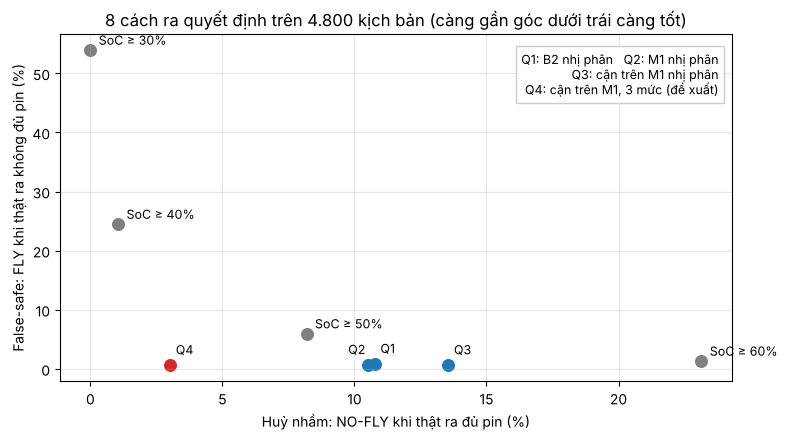

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in CACH:
    r = ket_qua.loc[c]
    mau = "tab:gray" if c.startswith("Q0") else ("tab:red" if c.startswith("Q4") else "tab:blue")
    ax.scatter(r["Huỷ nhầm (NO-FLY khi đủ pin)"] * 100, r["False-safe (FLY khi không đủ pin)"] * 100, s=70, color=mau)
    nhan = c.replace("Q0 ", "") if c.startswith("Q0") else c[:2]
    lech = {"Q1": (4, 8), "Q2": (-14, 8), "Q3": (4, 8), "Q4": (4, 8)}.get(c[:2], (6, 4))
    ax.annotate(nhan, (r["Huỷ nhầm (NO-FLY khi đủ pin)"] * 100, r["False-safe (FLY khi không đủ pin)"] * 100),
                textcoords="offset points", xytext=lech, fontsize=9)
ax.set_xlabel("Huỷ nhầm: NO-FLY khi thật ra đủ pin (%)")
ax.set_ylabel("False-safe: FLY khi thật ra không đủ pin (%)")
ax.set_title("8 cách ra quyết định trên 4.800 kịch bản (càng gần góc dưới trái càng tốt)")
ax.text(0.98, 0.95, "Q1: B2 nhị phân   Q2: M1 nhị phân\nQ3: cận trên M1 nhị phân\nQ4: cận trên M1, 3 mức (đề xuất)", transform=ax.transAxes, ha="right", va="top", fontsize=9, bbox=dict(fc="white", ec="0.8"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "decision_tradeoff.png", dpi=150)
plt.show()

## 6. Ca lỗi: false-safe nằm ở đâu?

In [7]:
loi = kb.assign(v=phan_quyet(kb, "Q2 M1 nhị phân"))
loi = loi[loi["khong_du"] & (loi["v"] == "FLY")]
print("False-safe của Q2 theo tuyến:")
print(loi["route"].where(loi["route"] == "R6", "R1–R5").value_counts())
loi3 = kb.assign(v=phan_quyet(kb, "Q4 Cận trên M1 3 mức"))
loi3 = loi3[loi3["khong_du"] & (loi3["v"] == "FLY")]
print("\nFalse-safe của Q4 theo tuyến:")
print(loi3["route"].where(loi3["route"] == "R6", "R1–R5").value_counts())
loi3[["flight", "route", "speed", "payload", "altitude", "E_Wh", "U_M1", "E_avail"]].round(1).head(10)

False-safe của Q2 theo tuyến:
route
R6    12
Name: count, dtype: int64

False-safe của Q4 theo tuyến:
route
R6    11
Name: count, dtype: int64


,flight,route,speed,payload,altitude,E_Wh,U_M1,E_avail
4609,268,R6,6.0,500.0,25,28.7,21.8,28.5
4611,268,R6,6.0,500.0,25,28.7,21.8,27.7
4617,268,R6,6.0,500.0,25,28.7,21.8,28.0
4692,271,R6,10.0,0.0,25,18.4,13.1,17.6
4701,272,R6,4.0,250.0,50,37.7,26.9,35.9
4702,272,R6,4.0,250.0,50,37.7,26.9,33.9
4703,272,R6,4.0,250.0,50,37.7,26.9,35.9
4707,272,R6,4.0,250.0,50,37.7,26.9,37.1
4708,272,R6,4.0,250.0,50,37.7,26.9,37.3
4713,272,R6,4.0,250.0,50,37.7,26.9,32.8


## 7. Độ bền: đổi giả định có làm đảo kết luận không?

- Pin 129,96 Wh (TB48D) thay cho 99,9 Wh
- Hệ số dự trữ 1,1 và 1,3 thay cho 1,2
- SoC đo sai ±5 điểm % (người vận hành đọc SoC lệch)
- Seed kịch bản khác (302 – 305)

In [8]:
def mot_lan(e_nom=E_NOM, du_tru=DU_TRU, sai_soc=0.0, seed=SEED):
    k = sinh_kich_ban(seed)
    k["E_avail"] = e_avail(k, e_nom)
    k["khong_du"] = k["E_Wh"] > k["E_avail"]
    rng = np.random.default_rng(seed + 1000)
    soc_doc = np.clip(k["soc"] + rng.uniform(-sai_soc, sai_soc, len(k)), 0, 1)
    k_doc = k.assign(soc=soc_doc)
    e_doc = e_avail(k_doc, e_nom)
    hang = {}
    for c in ["Q0 SoC ≥ 50%", "Q2 M1 nhị phân", "Q4 Cận trên M1 3 mức"]:
        d = danh_gia(k, phan_quyet(k_doc, c, e_doc, du_tru), k["khong_du"])
        hang[c] = f"{d['False-safe (FLY khi không đủ pin)'] * 100:.1f}% / {d['Huỷ nhầm (NO-FLY khi đủ pin)'] * 100:.1f}%"
    return hang

ben = {
    "Gốc (99,9 Wh, dự trữ 1,2)": mot_lan(),
    "Pin 129,96 Wh": mot_lan(e_nom=129.96),
    "Dự trữ 1,1": mot_lan(du_tru=1.1),
    "Dự trữ 1,3": mot_lan(du_tru=1.3),
    "SoC đo sai ±5%": mot_lan(sai_soc=0.05),
}
for s in range(302, 306):
    ben[f"Seed {s}"] = mot_lan(seed=s)
ben = pd.DataFrame(ben).T
ben.to_csv(ROOT / "reports" / "decision_robustness.csv", encoding="utf-8-sig")
print("Mỗi ô: false-safe / huỷ nhầm")
ben

Mỗi ô: false-safe / huỷ nhầm


,Q0 SoC ≥ 50%,Q2 M1 nhị phân,Q4 Cận trên M1 3 mức
"Gốc (99,9 Wh, dự trữ 1,2)",5.9% / 8.2%,0.6% / 10.5%,0.6% / 3.0%
"Pin 129,96 Wh",1.2% / 15.8%,0.3% / 7.5%,0.3% / 2.3%
"Dự trữ 1,1",5.9% / 8.2%,0.9% / 5.3%,0.8% / 3.0%
"Dự trữ 1,3",5.9% / 8.2%,0.5% / 15.3%,0.4% / 3.0%
SoC đo sai ±5%,6.6% / 8.8%,0.8% / 10.2%,0.6% / 3.9%
Seed 302,5.7% / 8.7%,0.3% / 11.9%,0.3% / 3.5%
Seed 303,6.0% / 8.4%,0.3% / 11.3%,0.3% / 3.6%
Seed 304,5.6% / 8.7%,0.1% / 11.8%,0.0% / 3.0%
Seed 305,6.7% / 9.0%,0.4% / 11.3%,0.2% / 3.1%


## 8. Kết luận

Xem bảng ở mục 3 và 7. Các con số cụ thể được đưa vào paper (mục Kết quả). Nhắc lại giới hạn: trạng thái pin là **mô phỏng**, chỉ năng lượng chuyến bay là đo thật; kết quả không phải chứng nhận an toàn bay.